In [1]:
import pandas as pd

In [42]:
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('train.csv', index_col='Row ID')

In [30]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Year"] = df["Order Date"].dt.year

In [34]:
df

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year
Row ID,,,,,,,,,,,,,,,,,,
1,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017
2,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017
3,CA-2017-138688,2017-06-12,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017
4,US-2016-108966,2016-10-11,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016
5,US-2016-108966,2016-10-11,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9796,CA-2017-125920,2017-05-21,28/05/2017,Standard Class,SH-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,OFF-BI-10003429,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.7980,2017
9797,CA-2016-128608,2016-01-12,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,OFF-AR-10001374,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.3680,2016
9798,CA-2016-128608,2016-01-12,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10004977,Technology,Phones,GE 30524EE4,235.1880,2016


In [38]:
# Q1: Which customers contributed the most to overall sales in 2017?
fil = df['Year'] == 2017
cus_2017_gr = df.loc[fil].groupby(['Customer ID', 'Customer Name'], as_index=False)


In [40]:
cus_2017_sales = cus_2017_gr['Sales'].sum().sort_values(by='Sales', ascending=False)
cus_2017_sales['Year'] = 2017

In [41]:
cus_2017_sales

,Customer ID,Customer Name,Sales,Year
595,TC-20980,Tamara Chand,18344.052,2017
109,CC-12370,Christopher Conant,11901.184,2017
6,AB-10105,Adrian Barton,10403.865,2017
547,SE-20110,Sanjit Engle,9879.220,2017
87,BS-11365,Bill Shonely,9199.780,2017
...,...,...,...,...
532,RW-19690,Robert Waldorf,3.282,2017
77,BM-11650,Brian Moss,2.907,2017
332,JW-15955,Joni Wasserman,2.610,2017
554,SH-20395,Shahid Hopkins,2.214,2017


In [43]:
top10 = cus_2017_sales.head(10)

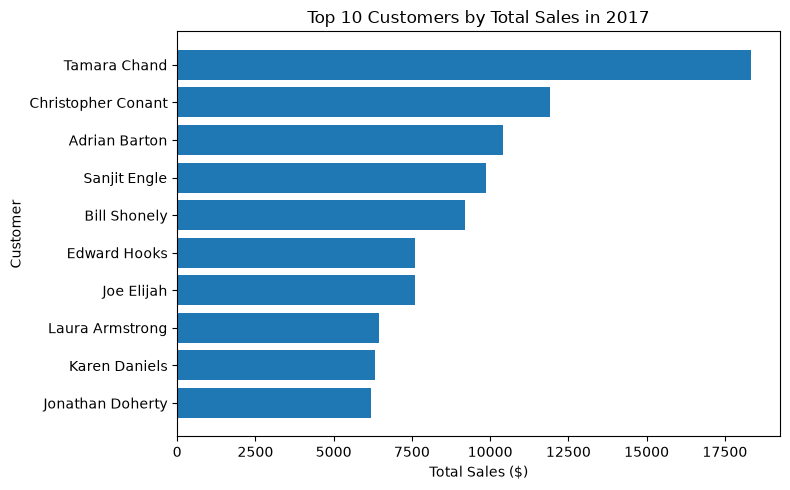

In [46]:
plt.figure(figsize=(8, 5))
plt.barh(top10['Customer Name'], top10['Sales'])
plt.gca().invert_yaxis()
plt.title("Top 10 Customers by Total Sales in 2017")
plt.xlabel("Total Sales ($)")
plt.ylabel("Customer")
plt.tight_layout()
plt.savefig("top_customers_2017.png", dpi=150)
plt.show()

In [27]:
# Q2: Which state generated the most sales in each year?
year_state_gr = df.groupby(['Year', 'State'], as_index=False)

In [48]:
year_state_sales = year_state_gr['Sales'].sum().sort_values(by=['Year', 'Sales'], ascending=[True, False])

In [50]:
year_totals = df.groupby(['Year'], as_index=False)['Sales'].sum()
year_totals = year_totals.rename(columns={'Sales': 'Year Total Sales'})

In [51]:
year_state_sales = year_state_sales.merge(year_totals, on='Year')

In [52]:
year_state_sales['Percent'] = year_state_sales['Sales'] / year_state_sales['Year Total Sales'] * 100

In [53]:
year_state_sales

,Year,State,Sales,Year Total Sales,Percent
0,2015,California,89475.1490,479856.2081,18.646242
1,2015,New York,64346.0670,479856.2081,13.409448
2,2015,Texas,50139.4886,479856.2081,10.448857
3,2015,Florida,34223.0125,479856.2081,7.131931
4,2015,Washington,29871.5760,479856.2081,6.225110
...,...,...,...,...,...
176,2018,North Dakota,919.9100,722052.0192,0.127402
177,2018,Vermont,842.2100,722052.0192,0.116641
178,2018,Kansas,733.1500,722052.0192,0.101537
179,2018,Iowa,580.2100,722052.0192,0.080356


In [54]:
year = 2015
data = year_state_sales[year_state_sales['Year'] == year].head(5)

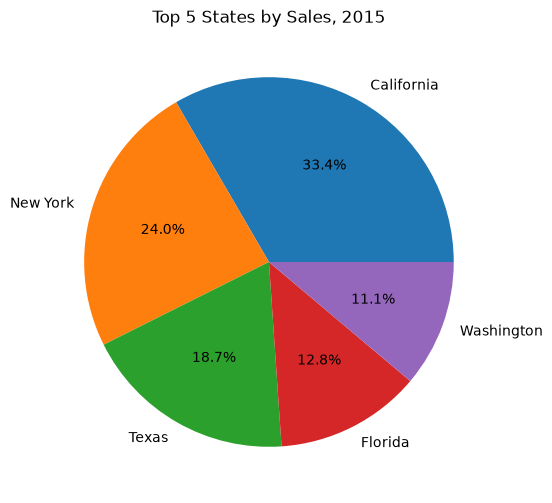

In [55]:
plt.figure(figsize=(6, 6))
plt.pie(data['Sales'], labels=data['State'], autopct='%1.1f%%')
plt.title(f'Top 5 States by Sales, {year}')
plt.savefig(f'state_share_{year}.png')
plt.show()